<a href="https://colab.research.google.com/github/aakankshalahane/NLP-Projects-/blob/main/Named_Entity_Recognition_(NER).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Installing spaCy for our NLP project

!pip install spacy

# Downloading a pre-trained English language model
!python -m spacy download en_core_web_sm

print("spaCy is ready to use!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 135.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy is ready to use!


In [ ]:
# Importing the libraries we need

import spacy
import pandas as pd

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
# Loading the English NLP model

nlp = spacy.load("en_core_web_sm")

print("English NLP model loaded successfully!")


English NLP model loaded successfully!


In [ ]:
# Creating sample sentences for entity recognition

sentences = [
    "Sundar Pichai is the CEO of Google.",
    "Elon Musk founded SpaceX in the United States.",
    "Microsoft opened a new office in Berlin.",
    "Marie Curie was born in Warsaw in 1867.",
    "Apple launched a new product in California.",
    "Aakanksha is learning Artificial Intelligence in India.",
    "Amazon announced a new project in London.",
    "Albert Einstein was born in Germany.",
    "OpenAI developed ChatGPT in San Francisco.",
    "The conference will take place in Munich on 15 June 2026."
]

# Displaying our sentences

for number, sentence in enumerate(sentences, start=1):
    print(number, sentence)


1 Sundar Pichai is the CEO of Google.
2 Elon Musk founded SpaceX in the United States.
3 Microsoft opened a new office in Berlin.
4 Marie Curie was born in Warsaw in 1867.
5 Apple launched a new product in California.
6 Aakanksha is learning Artificial Intelligence in India.
7 Amazon announced a new project in London.
8 Albert Einstein was born in Germany.
9 OpenAI developed ChatGPT in San Francisco.
10 The conference will take place in Munich on 15 June 2026.


In [ ]:
# Identifying names, companies, places and dates

for sentence in sentences:

    # Processing the sentence using spaCy
    doc = nlp(sentence)

    print("\nSentence:", sentence)

    # Finding the entities
    for entity in doc.ents:

        print("Entity:", entity.text)
        print("Category:", entity.label_)
        print("Meaning:", spacy.explain(entity.label_))
        print("----------------------")



Sentence: Sundar Pichai is the CEO of Google.
Entity: Sundar Pichai
Category: PERSON
Meaning: People, including fictional
----------------------
Entity: Google
Category: ORG
Meaning: Companies, agencies, institutions, etc.
----------------------

Sentence: Elon Musk founded SpaceX in the United States.
Entity: Elon Musk
Category: PERSON
Meaning: People, including fictional
----------------------
Entity: the United States
Category: GPE
Meaning: Countries, cities, states
----------------------

Sentence: Microsoft opened a new office in Berlin.
Entity: Microsoft
Category: ORG
Meaning: Companies, agencies, institutions, etc.
----------------------
Entity: Berlin
Category: GPE
Meaning: Countries, cities, states
----------------------

Sentence: Marie Curie was born in Warsaw in 1867.
Entity: Marie Curie
Category: PERSON
Meaning: People, including fictional
----------------------
Entity: Warsaw
Category: GPE
Meaning: Countries, cities, states
----------------------
Entity: 1867
Category: D

In [ ]:

# Creating an empty list to store annotations

annotation_data = []

# Going through each sentence
for sentence in sentences:

    doc = nlp(sentence)

    # Extracting every identified entity
    for entity in doc.ents:

        annotation_data.append({

            "Sentence": sentence,

            "Entity_Text": entity.text,

            "Entity_Label": entity.label_,

            "Entity_Meaning": spacy.explain(entity.label_),

            "Start_Position": entity.start_char,

            "End_Position": entity.end_char

        })

# Converting the list into a DataFrame
annotation_df = pd.DataFrame(annotation_data)

# Displaying the final annotation table
annotation_df


,Sentence,Entity_Text,Entity_Label,Entity_Meaning,Start_Position,End_Position
0,Sundar Pichai is the CEO of Google.,Sundar Pichai,PERSON,"People, including fictional",0,13
1,Sundar Pichai is the CEO of Google.,Google,ORG,"Companies, agencies, institutions, etc.",28,34
2,Elon Musk founded SpaceX in the United States.,Elon Musk,PERSON,"People, including fictional",0,9
3,Elon Musk founded SpaceX in the United States.,the United States,GPE,"Countries, cities, states",28,45
4,Microsoft opened a new office in Berlin.,Microsoft,ORG,"Companies, agencies, institutions, etc.",0,9
5,Microsoft opened a new office in Berlin.,Berlin,GPE,"Countries, cities, states",33,39
6,Marie Curie was born in Warsaw in 1867.,Marie Curie,PERSON,"People, including fictional",0,11
7,Marie Curie was born in Warsaw in 1867.,Warsaw,GPE,"Countries, cities, states",24,30
8,Marie Curie was born in Warsaw in 1867.,1867,DATE,Absolute or relative dates or periods,34,38
9,Apple launched a new product in California.,Apple,ORG,"Companies, agencies, institutions, etc.",0,5


In [14]:
# Count how many times each entity label appears
entity_summary = annotation_df["Entity_Label"].value_counts()

# Display the entity summary
print(entity_summary)

Entity_Label
GPE       9
ORG       6
PERSON    5
DATE      2
Name: count, dtype: int64


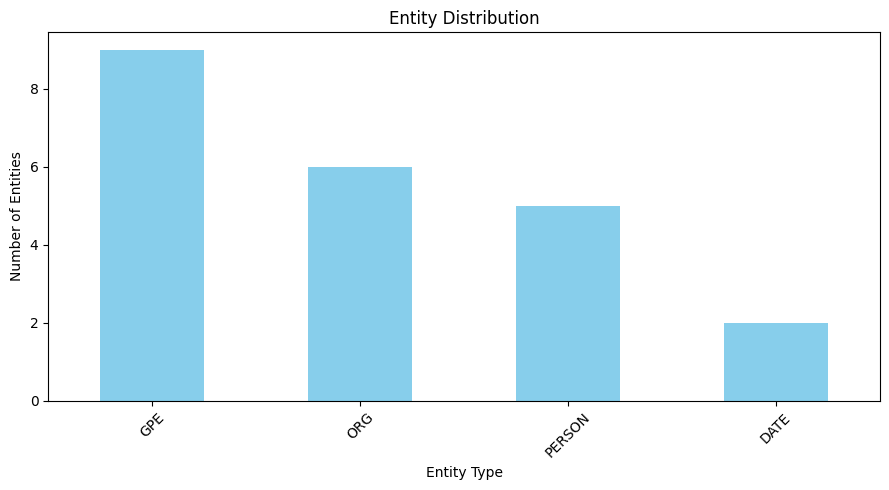

In [15]:
import matplotlib.pyplot as plt

entity_summary.plot(
    kind="bar",
    figsize=(9, 5),
    color="skyblue"
)

plt.title("Entity Distribution")
plt.xlabel("Entity Type")
plt.ylabel("Number of Entities")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

# Creating a human review column

annotation_df["Human_Review"] = "Pending"

# Creating a column for corrected entity labels
annotation_df["Corrected_Label"] = annotation_df["Entity_Label"]

# Displaying the review table
annotation_df.head(15)


,Sentence,Entity_Text,Entity_Label,Entity_Meaning,Start_Position,End_Position,Human_Review,Corrected_Label
0,Sundar Pichai is the CEO of Google.,Sundar Pichai,PERSON,"People, including fictional",0,13,Pending,PERSON
1,Sundar Pichai is the CEO of Google.,Google,ORG,"Companies, agencies, institutions, etc.",28,34,Pending,ORG
2,Elon Musk founded SpaceX in the United States.,Elon Musk,PERSON,"People, including fictional",0,9,Pending,PERSON
3,Elon Musk founded SpaceX in the United States.,the United States,GPE,"Countries, cities, states",28,45,Pending,GPE
4,Microsoft opened a new office in Berlin.,Microsoft,ORG,"Companies, agencies, institutions, etc.",0,9,Pending,ORG
5,Microsoft opened a new office in Berlin.,Berlin,GPE,"Countries, cities, states",33,39,Pending,GPE
6,Marie Curie was born in Warsaw in 1867.,Marie Curie,PERSON,"People, including fictional",0,11,Pending,PERSON
7,Marie Curie was born in Warsaw in 1867.,Warsaw,GPE,"Countries, cities, states",24,30,Pending,GPE
8,Marie Curie was born in Warsaw in 1867.,1867,DATE,Absolute or relative dates or periods,34,38,Pending,DATE
9,Apple launched a new product in California.,Apple,ORG,"Companies, agencies, institutions, etc.",0,5,Pending,ORG


In [ ]:

# Example of correcting an annotation

# Displaying the first few records
print(annotation_df.head())

# Example: mark all current predictions as reviewed
# Only do this after checking the entities yourself.

annotation_df.loc[
    annotation_df["Entity_Text"] == "Google",
    "Human_Review"
] = "Reviewed"

print("\nUpdated annotation:")
annotation_df[
    annotation_df["Entity_Text"] == "Google"
]


                                         Sentence        Entity_Text  \
0             Sundar Pichai is the CEO of Google.      Sundar Pichai   
1             Sundar Pichai is the CEO of Google.             Google   
2  Elon Musk founded SpaceX in the United States.          Elon Musk   
3  Elon Musk founded SpaceX in the United States.  the United States   
4        Microsoft opened a new office in Berlin.          Microsoft   

  Entity_Label                           Entity_Meaning  Start_Position  \
0       PERSON              People, including fictional               0   
1          ORG  Companies, agencies, institutions, etc.              28   
2       PERSON              People, including fictional               0   
3          GPE                Countries, cities, states              28   
4          ORG  Companies, agencies, institutions, etc.               0   

   End_Position Human_Review Corrected_Label  
0            13      Pending          PERSON  
1            34      P

,Sentence,Entity_Text,Entity_Label,Entity_Meaning,Start_Position,End_Position,Human_Review,Corrected_Label
1,Sundar Pichai is the CEO of Google.,Google,ORG,"Companies, agencies, institutions, etc.",28,34,Reviewed,ORG


In [ ]:

# Saving our annotation results

annotation_df.to_csv(
    "NER_Annotated_Dataset.csv",
    index=False
)

print("NER dataset exported successfully!")


NER dataset exported successfully!


In [ ]:

# Downloading the CSV file to your computer

from google.colab import files

files.download("NER_Annotated_Dataset.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Generating a small project summary

print("PROJECT: NAMED ENTITY RECOGNITION")

print("----------------------------------")

print("Total Sentences:", len(sentences))

print("Total Entities Identified:", len(annotation_df))

print("Total Entity Categories:",
      annotation_df["Entity_Label"].nunique())

print("\nEntity Distribution:")

print(annotation_df["Entity_Label"].value_counts())

print("\nHuman Review Status:")

print(annotation_df["Human_Review"].value_counts())

print("----------------------------------")

print("Project completed successfully!")


PROJECT: NAMED ENTITY RECOGNITION
----------------------------------
Total Sentences: 10
Total Entities Identified: 22
Total Entity Categories: 4

Entity Distribution:
Entity_Label
GPE       9
ORG       6
PERSON    5
DATE      2
Name: count, dtype: int64

Human Review Status:
Human_Review
Pending     21
Reviewed     1
Name: count, dtype: int64
----------------------------------
Project completed successfully!
